# Q3 — Abstractive Text Summarization with a Transformer

This notebook implements the CNN/DailyMail 3.0.0 summarization task end to end. It builds the encoder, decoder, attention, feed-forward blocks, positional encodings, masks, training loop, and greedy decoding using basic PyTorch layers and tensor operations. The `bert-base-uncased` checkpoint is used **only as a tokenizer**; no pretrained model weights are loaded.

## How to run

1. Open this notebook in Google Colab and select **Runtime → Change runtime type → T4 GPU** (or another GPU).
2. Run cells from top to bottom. The first cells install packages and download the tokenizer and dataset.
3. The notebook defaults to all official splits (287,113 train / 13,368 validation / 11,490 test), 12 epochs, and may take several hours on a T4. It mounts Google Drive and saves epoch checkpoints there so training can resume after a runtime restart. Reduce split sizes only for a clearly labeled trial.
4. The final cell downloads a ZIP containing the best model, resumable optimizer/scaler checkpoint, tokenizer, full per-test predictions, metrics, report, and plots.

**Compute warning:** Full greedy decoding for 11,490 test examples and training on all 287,113 training articles can take a long time. 

In [1]:
%pip -q install "transformers>=5.0" "datasets>=4.0" "huggingface-hub>=1.16" "fsspec==2025.12.0" "pyarrow>=19,<24" rouge-score matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Configuration and imports

In [ ]:
import contextlib
import csv
import json
import math
import random
import re
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from datasets import load_dataset
from rouge_score import rouge_scorer
from torch import nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer
from tqdm.auto import tqdm

SEED = 42
TOKENIZER_NAME = "bert-base-uncased"
MAX_SOURCE_LENGTH = 512
MAX_TARGET_LENGTH = 128

# Full assignment splits
TRAIN_SIZE = 287_113
VALIDATION_SIZE = 13_368
TEST_SIZE = 11_490  
EPOCHS = 12
BATCH_SIZE = 4
GRAD_ACCUM_STEPS = 4  
D_MODEL = 128
NUM_HEADS = 4
ENCODER_LAYERS = 2
DECODER_LAYERS = 2
D_FF = 512
DROPOUT = 0.1
WARMUP_STEPS = 4_000
LR_SCALE = 0.5
EARLY_STOPPING_PATIENCE = 3
RESUME_TRAINING = False  # Set True only after restoring training_checkpoint.pt from a prior run.
OUTPUT_DIR = Path("/kaggle/working/Q3_Summarization_Artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cuda.matmul.allow_tf32 = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print(
    f"Planned examples: train={TRAIN_SIZE:,}, validation={VALIDATION_SIZE:,}, "
    f"test={'full' if TEST_SIZE is None else f'{TEST_SIZE:,}'}; epochs={EPOCHS}"
)

Device: cuda
GPU: Tesla T4
Planned examples: train=287,113, validation=13,368, test=11,490; epochs=12


## 2. Load and tokenize CNN/DailyMail

The official train, validation, and test splits remain separate. The tokenizer lowercases text, uses a shared WordPiece vocabulary, and inserts `[CLS]`/`[SEP]`; summaries are truncated to 128 tokens and articles to 512. Padding is dynamic within each batch to avoid wasted computation. The reference summary text is retained verbatim (including its newlines) for ROUGE-Lsum and qualitative reporting.

In [3]:
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME, use_fast=True)
if not tokenizer.is_fast:
    raise RuntimeError("The fast tokenizer is required for attention token labels.")


def load_tokenized_split(split_name, limit):
    if limit is not None and (isinstance(limit, bool) or not isinstance(limit, int)):
        raise TypeError(
            f"{split_name} size must be an integer or None, got {limit!r}. "
            "Use underscores for digit grouping (for example 287_113), not commas."
        )
    if limit is not None and limit < 0:
        raise ValueError(f"{split_name} size cannot be negative: {limit}")

    split = load_dataset("abisee/cnn_dailymail", "3.0.0", split=split_name)
    split = split.shuffle(seed=SEED)
    if limit is not None:
        split = split.select(range(min(limit, len(split))))

    def tokenize_batch(batch):
        source = tokenizer(
            batch["article"],
            max_length=MAX_SOURCE_LENGTH,
            truncation=True,
            padding=False,
        )
        target = tokenizer(
            batch["highlights"],
            max_length=MAX_TARGET_LENGTH,
            truncation=True,
            padding=False,
        )
        return {"input_ids": source["input_ids"], "target_ids": target["input_ids"]}

    return split.map(
        tokenize_batch,
        batched=True,
        desc=f"Tokenizing {split_name}",
        load_from_cache_file=True,
    )


train_data = load_tokenized_split("train", TRAIN_SIZE)
validation_data = load_tokenized_split("validation", VALIDATION_SIZE)
test_data = load_tokenized_split("test", TEST_SIZE)
print(
    f"Examples — train: {len(train_data):,}; validation: {len(validation_data):,}; "
    f"test: {len(test_data):,}"
)
print("Tokenizer:", TOKENIZER_NAME, "| Vocabulary:", len(tokenizer))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

...

Generating test split:   0%|          | 0/11490 [00:00<?, ? examples/s]

Tokenizing train:   0%|          | 0/287113 [00:00<?, ? examples/s]

Tokenizing validation:   0%|          | 0/13368 [00:00<?, ? examples/s]

Tokenizing test:   0%|          | 0/11490 [00:00<?, ? examples/s]

Examples — train: 287,113; validation: 13,368; test: 11,490
Tokenizer: bert-base-uncased | Vocabulary: 30522


## 3. Transformer implementation from scratch

Attention uses the scaled dot-product equation, implemented explicitly with linear projections, `matmul`, masking, and `softmax`. The decoder's self-attention combines the causal look-ahead mask with target padding. Encoder self-attention and cross-attention mask source padding. This deliberately does not use `nn.Transformer`, `nn.MultiheadAttention`, or fused scaled-dot-product attention.

In [4]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_length, dropout):
        super().__init__()
        positions = torch.arange(max_length, dtype=torch.float32).unsqueeze(1)
        scales = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )
        encoding = torch.zeros(max_length, d_model)
        encoding[:, 0::2] = torch.sin(positions * scales)
        encoding[:, 1::2] = torch.cos(
            positions * scales[: encoding[:, 1::2].shape[1]]
        )
        self.register_buffer("encoding", encoding.unsqueeze(0), persistent=False)
        self.dropout = nn.Dropout(dropout)

    def forward(self, inputs):
        if inputs.size(1) > self.encoding.size(1):
            raise ValueError("Input sequence exceeds configured positional length.")
        return self.dropout(inputs + self.encoding[:, : inputs.size(1)])


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout):
        super().__init__()
        if d_model % num_heads:
            raise ValueError("d_model must be divisible by num_heads.")
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads
        self.query = nn.Linear(d_model, d_model)
        self.key = nn.Linear(d_model, d_model)
        self.value = nn.Linear(d_model, d_model)
        self.output = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, query, key, value, mask=None):
        batch_size, query_length, _ = query.shape

        def split_heads(tensor):
            return tensor.reshape(
                batch_size, -1, self.num_heads, self.head_dim
            ).transpose(1, 2)

        queries = split_heads(self.query(query))
        keys = split_heads(self.key(key))
        values = split_heads(self.value(value))
        scores = torch.matmul(queries, keys.transpose(-2, -1))
        scores = scores / math.sqrt(self.head_dim)
        if mask is not None:
            scores = scores.masked_fill(mask, torch.finfo(scores.dtype).min)
        weights = torch.softmax(scores, dim=-1)
        attended = torch.matmul(self.dropout(weights), values)
        attended = attended.transpose(1, 2).contiguous().reshape(
            batch_size, query_length, self.num_heads * self.head_dim
        )
        return self.output(attended), weights


class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model),
        )

    def forward(self, inputs):
        return self.layers(inputs)


class EncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout):
        super().__init__()
        self.attention = MultiHeadAttention(d_model, num_heads, dropout)
        self.feed_forward = FeedForward(d_model, d_ff, dropout)
        self.norm_attention = nn.LayerNorm(d_model)
        self.norm_feed_forward = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, inputs, source_padding_mask):
        attended, _ = self.attention(
            inputs, inputs, inputs, source_padding_mask
        )
        inputs = self.norm_attention(inputs + self.dropout(attended))
        return self.norm_feed_forward(
            inputs + self.dropout(self.feed_forward(inputs))
        )


class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout):
        super().__init__()
        self.self_attention = MultiHeadAttention(d_model, num_heads, dropout)
        self.cross_attention = MultiHeadAttention(d_model, num_heads, dropout)
        self.feed_forward = FeedForward(d_model, d_ff, dropout)
        self.norm_self = nn.LayerNorm(d_model)
        self.norm_cross = nn.LayerNorm(d_model)
        self.norm_feed_forward = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, inputs, memory, target_mask, source_padding_mask):
        attended, _ = self.self_attention(
            inputs, inputs, inputs, target_mask
        )
        inputs = self.norm_self(inputs + self.dropout(attended))
        attended, cross_weights = self.cross_attention(
            inputs, memory, memory, source_padding_mask
        )
        inputs = self.norm_cross(inputs + self.dropout(attended))
        inputs = self.norm_feed_forward(
            inputs + self.dropout(self.feed_forward(inputs))
        )
        return inputs, cross_weights


class TransformerSummarizer(nn.Module):
    def __init__(
        self,
        vocab_size,
        pad_id,
        d_model=128,
        num_heads=4,
        encoder_layers=2,
        decoder_layers=2,
        d_ff=512,
        dropout=0.1,
        max_length=512,
    ):
        super().__init__()
        self.pad_id = pad_id
        self.d_model = d_model
        self.embedding = nn.Embedding(
            vocab_size, d_model, padding_idx=pad_id
        )
        self.position = PositionalEncoding(d_model, max_length, dropout)
        self.encoder = nn.ModuleList(
            [
                EncoderLayer(d_model, num_heads, d_ff, dropout)
                for _ in range(encoder_layers)
            ]
        )
        self.decoder = nn.ModuleList(
            [
                DecoderLayer(d_model, num_heads, d_ff, dropout)
                for _ in range(decoder_layers)
            ]
        )
        self.output = nn.Linear(d_model, vocab_size)

    def encode(self, source):
        source_padding_mask = (source == self.pad_id)[:, None, None, :]
        memory = self.position(
            self.embedding(source) * math.sqrt(self.d_model)
        )
        for layer in self.encoder:
            memory = layer(memory, source_padding_mask)
        return memory, source_padding_mask

    def decode(self, target, memory, source_padding_mask):
        length = target.size(1)
        causal_mask = torch.triu(
            torch.ones(
                length, length, dtype=torch.bool, device=target.device
            ),
            diagonal=1,
        )
        target_padding_mask = (target == self.pad_id)[:, None, None, :]
        target_mask = causal_mask[None, None, :, :] | target_padding_mask
        decoded = self.position(
            self.embedding(target) * math.sqrt(self.d_model)
        )
        cross_weights = None
        for layer in self.decoder:
            decoded, cross_weights = layer(
                decoded, memory, target_mask, source_padding_mask
            )
        return self.output(decoded), cross_weights

    def forward(self, source, target):
        memory, source_padding_mask = self.encode(source)
        return self.decode(target, memory, source_padding_mask)

    @property
    def parameter_count(self):
        return sum(
            parameter.numel()
            for parameter in self.parameters()
            if parameter.requires_grad
        )

### Model smoke test

In [5]:
model = TransformerSummarizer(
    vocab_size=len(tokenizer),
    pad_id=tokenizer.pad_token_id,
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    encoder_layers=ENCODER_LAYERS,
    decoder_layers=DECODER_LAYERS,
    d_ff=D_FF,
    dropout=DROPOUT,
    max_length=MAX_SOURCE_LENGTH,
).to(DEVICE)
sample_source = torch.tensor(
    [tokenizer("A short news article.", max_length=8, truncation=True,
               padding="max_length")["input_ids"]],
    device=DEVICE,
)
sample_target = torch.tensor(
    [tokenizer("A brief summary.", max_length=6, truncation=True,
               padding="max_length")["input_ids"][:-1]],
    device=DEVICE,
)
with torch.no_grad():
    sample_logits, sample_attention = model(sample_source, sample_target)
assert sample_logits.shape == (1, sample_target.size(1), len(tokenizer))
assert sample_attention.shape == (
    1, NUM_HEADS, sample_target.size(1), sample_source.size(1)
)
assert torch.all(sample_attention[..., sample_source[0].eq(tokenizer.pad_token_id)] == 0)
model.eval()
with torch.no_grad():
    sample_memory, sample_source_mask = model.encode(sample_source)
    changed_future = sample_target.clone()
    changed_future[:, -1] = (changed_future[:, -1] + 1) % len(tokenizer)
    logits_a, _ = model.decode(sample_target, sample_memory, sample_source_mask)
    logits_b, _ = model.decode(changed_future, sample_memory, sample_source_mask)
torch.testing.assert_close(logits_a[:, :1], logits_b[:, :1], rtol=0, atol=0)
print("Causal mask prevents future-token leakage.")
print("Forward pass and source padding mask passed.")
print("Trainable parameters:", f"{model.parameter_count:,}")

Causal mask prevents future-token leakage.
Forward pass and source padding mask passed.
Trainable parameters: 8,769,850


## 4. Train with teacher forcing

For every gold summary, the decoder receives `[CLS] ...` (the summary shifted right) and predicts the next token, including `[SEP]`. Padding is excluded from cross-entropy. The revised run uses 12 maximum epochs, a 4,000-step warmup and a 0.5 Noam rate scale, fp16 mixed precision on CUDA, dynamic batch padding, and gradient accumulation (effective batch size 16). Validation loss selects the best checkpoint and triggers early stopping; the test set is not consulted during training or model selection. An optimizer/scaler checkpoint is saved after every epoch to Google Drive.

In [6]:
class SummaryDataset(Dataset):
    def __init__(self, hf_split):
        self.split = hf_split

    def __len__(self):
        return len(self.split)

    def __getitem__(self, index):
        row = self.split[index]
        return (
            torch.tensor(row["input_ids"], dtype=torch.long),
            torch.tensor(row["target_ids"], dtype=torch.long),
        )


def collate_summaries(batch):
    sources, targets = zip(*batch)
    return (
        pad_sequence(sources, batch_first=True, padding_value=tokenizer.pad_token_id),
        pad_sequence(targets, batch_first=True, padding_value=tokenizer.pad_token_id),
    )


train_loader = DataLoader(
    SummaryDataset(train_data),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_summaries,
    num_workers=2,
    pin_memory=DEVICE.type == "cuda",
    persistent_workers=True,
)
validation_loader = DataLoader(
    SummaryDataset(validation_data),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_summaries,
    num_workers=2,
    pin_memory=DEVICE.type == "cuda",
    persistent_workers=True,
)
optimizer = torch.optim.Adam(
    model.parameters(), lr=0.0, betas=(0.9, 0.98), eps=1e-9
)
scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
criterion = nn.CrossEntropyLoss(ignore_index=tokenizer.pad_token_id)

checkpoint_path = OUTPUT_DIR / "best_model.pt"
training_state_path = OUTPUT_DIR / "training_checkpoint.pt"
run_config = {
    "tokenizer": TOKENIZER_NAME,
    "vocab_size": len(tokenizer),
    "pad_id": tokenizer.pad_token_id,
    "max_source_length": MAX_SOURCE_LENGTH,
    "max_target_length": MAX_TARGET_LENGTH,
    "train_examples": len(train_data),
    "validation_examples": len(validation_data),
    "d_model": D_MODEL,
    "num_heads": NUM_HEADS,
    "encoder_layers": ENCODER_LAYERS,
    "decoder_layers": DECODER_LAYERS,
    "d_ff": D_FF,
    "dropout": DROPOUT,
    "batch_size": BATCH_SIZE,
    "gradient_accumulation_steps": GRAD_ACCUM_STEPS,
    "warmup_steps": WARMUP_STEPS,
    "lr_scale": LR_SCALE,
    "epochs": EPOCHS,
    "seed": SEED,
}

history = {
    "epoch": [],
    "train_loss": [],
    "validation_loss": [],
    "learning_rate": [],
    "epoch_seconds": [],
}
best_validation_loss = math.inf
best_epoch = 0
steps = 0
start_epoch = 1
epochs_without_improvement = 0

if RESUME_TRAINING:
    if not training_state_path.exists():
        raise FileNotFoundError(
            f"Cannot resume: checkpoint not found at {training_state_path}"
        )
    saved = torch.load(training_state_path, map_location=DEVICE, weights_only=False)
    if saved["run_config"] != run_config:
        raise ValueError(
            "Saved checkpoint configuration differs from this run. "
            "Restore the original data/model settings before resuming."
        )
    model.load_state_dict(saved["model_state_dict"])
    optimizer.load_state_dict(saved["optimizer_state_dict"])
    scaler.load_state_dict(saved["scaler_state_dict"])
    history = saved["history"]
    best_validation_loss = saved["best_validation_loss"]
    best_epoch = saved["best_epoch"]
    steps = saved["steps"]
    start_epoch = saved["completed_epoch"] + 1
    epochs_without_improvement = saved["epochs_without_improvement"]
    print(f"Resuming at epoch {start_epoch}.")
else:
    for stale_checkpoint in (checkpoint_path, training_state_path):
        if stale_checkpoint.exists():
            stale_checkpoint.unlink()


def run_epoch(loader, training, step_count=0):
    model.train(training)
    total_loss = 0.0
    total_tokens = 0
    num_batches = len(loader)
    optimizer.zero_grad(set_to_none=True) if training else None

    progress = tqdm(
        enumerate(loader),
        total=num_batches,
        desc="Training" if training else "Validation",
        leave=False,
    )
    for batch_index, (source, target) in progress:
        source = source.to(DEVICE, non_blocking=True)
        target = target.to(DEVICE, non_blocking=True)
        decoder_input = target[:, :-1]
        expected = target[:, 1:]
        group_start = (batch_index // GRAD_ACCUM_STEPS) * GRAD_ACCUM_STEPS
        group_size = min(GRAD_ACCUM_STEPS, num_batches - group_start)
        is_update_batch = (batch_index + 1) % GRAD_ACCUM_STEPS == 0 or batch_index + 1 == num_batches
        update_step = step_count + 1
        rate = LR_SCALE * D_MODEL ** -0.5 * min(
            update_step ** -0.5,
            update_step * WARMUP_STEPS ** -1.5,
        )
        if training:
            for group in optimizer.param_groups:
                group["lr"] = rate

        autocast = (
            torch.autocast(device_type="cuda", dtype=torch.float16)
            if DEVICE.type == "cuda"
            else contextlib.nullcontext()
        )
        with torch.set_grad_enabled(training):
            with autocast:
                logits, _ = model(source, decoder_input)
                loss = criterion(
                    logits.reshape(-1, logits.size(-1)),
                    expected.reshape(-1),
                )
            if training:
                scaler.scale(loss / group_size).backward()
                if is_update_batch:
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(optimizer)
                    scaler.update()
                    optimizer.zero_grad(set_to_none=True)
                    step_count = update_step

        valid_tokens = expected.ne(model.pad_id).sum().item()
        total_loss += loss.detach().float().item() * valid_tokens
        total_tokens += valid_tokens
        if training and batch_index % 100 == 0:
            progress.set_postfix(loss=f"{loss.item():.3f}", lr=f"{rate:.2e}")

    if total_tokens == 0:
        raise RuntimeError("No non-padding target tokens were found.")
    return total_loss / total_tokens, step_count


training_started_at = time.time()
for epoch in range(start_epoch, EPOCHS + 1):
    epoch_started_at = time.time()
    train_loss, steps = run_epoch(train_loader, training=True, step_count=steps)
    validation_loss, _ = run_epoch(validation_loader, training=False)
    epoch_seconds = time.time() - epoch_started_at
    current_lr = optimizer.param_groups[0]["lr"]
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["validation_loss"].append(validation_loss)
    history["learning_rate"].append(current_lr)
    history["epoch_seconds"].append(epoch_seconds)
    print(
        f"Epoch {epoch}/{EPOCHS}: train loss={train_loss:.4f}, "
        f"validation loss={validation_loss:.4f}, lr={current_lr:.2e}, "
        f"time={epoch_seconds / 60:.1f} min"
    )

    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        best_epoch = epoch
        epochs_without_improvement = 0
        torch.save(model.state_dict(), checkpoint_path)
    else:
        epochs_without_improvement += 1

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scaler_state_dict": scaler.state_dict(),
            "completed_epoch": epoch,
            "best_epoch": best_epoch,
            "best_validation_loss": best_validation_loss,
            "epochs_without_improvement": epochs_without_improvement,
            "steps": steps,
            "run_config": run_config,
            "history": history,
        },
        training_state_path,
    )
    (OUTPUT_DIR / "loss_history.json").write_text(
        json.dumps(history, indent=2), encoding="utf-8"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping: validation loss did not improve.")
        break

if best_epoch == 0 or not checkpoint_path.exists():
    raise RuntimeError("Training did not produce a best validation checkpoint.")
model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))
training_seconds = sum(history["epoch_seconds"])
print(
    f"Restored best epoch {best_epoch}; "
    f"best validation loss={best_validation_loss:.4f}"
)
print(f"Training time: {training_seconds / 60:.1f} minutes")

Training:   0%|          | 0/71779 [00:00<?, ?it/s]

Validation:   0%|          | 0/3342 [00:00<?, ?it/s]

Epoch 1/12: train loss=6.1261, validation loss=5.4735, lr=3.30e-04, time=29.8 min


Training:   0%|          | 0/71779 [00:00<?, ?it/s]

Validation:   0%|          | 0/3342 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/3342 [00:00<?, ?it/s]

Epoch 10/12: train loss=nan, validation loss=73.2792, lr=1.04e-04, time=29.2 min


Training:   0%|          | 0/71779 [00:00<?, ?it/s]

Validation:   0%|          | 0/3342 [00:00<?, ?it/s]

Epoch 11/12: train loss=nan, validation loss=73.2792, lr=9.95e-05, time=29.4 min
Early stopping: validation loss did not improve.
Restored best epoch 8; best validation loss=5.1243
Training time: 323.7 minutes


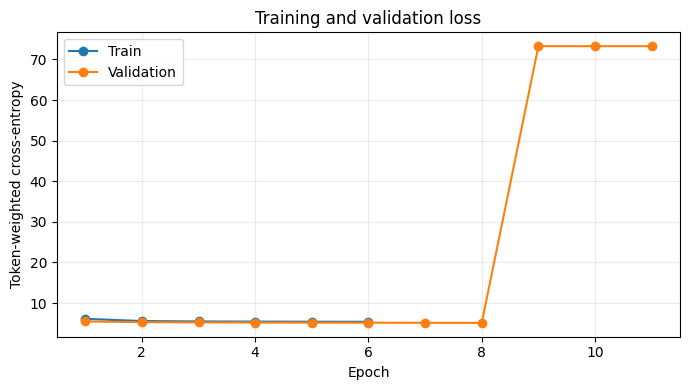

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], marker="o", label="Train")
plt.plot(range(1, len(history["validation_loss"]) + 1), history["validation_loss"], marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Token-weighted cross-entropy")
plt.title("Training and validation loss")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
LOSS_PLOT = OUTPUT_DIR / "training_curve.png"
plt.savefig(LOSS_PLOT, dpi=160)
plt.show()

## 5. Autoregressive greedy decoding and test ROUGE

The encoder output is computed once per article and reused at every generation step. ROUGE values are macro-averaged F1 on the configured test set. The default `TEST_SIZE = 11_490` evaluates the complete official test split; use `None` to load the full split without an explicit cap.

In [8]:
@torch.no_grad()
def generate_summary(source, max_length=MAX_TARGET_LENGTH, min_length=12, no_repeat_ngram_size=3):
    model.eval()
    source = source.to(DEVICE)
    memory, source_padding_mask = model.encode(source)
    generated = torch.tensor(
        [[tokenizer.cls_token_id]], dtype=torch.long, device=DEVICE
    )
    attention_rows = []
    forbidden_ids = {
        token_id
        for token_id in (tokenizer.pad_token_id, tokenizer.cls_token_id, tokenizer.mask_token_id)
        if token_id is not None
    }

    for _ in range(max_length - 1):
        logits, cross_attention = model.decode(
            generated, memory, source_padding_mask
        )
        next_logits = logits[:, -1, :].float().clone()
        for token_id in forbidden_ids:
            next_logits[:, token_id] = -torch.inf
        if generated.size(1) < min_length:
            next_logits[:, tokenizer.sep_token_id] = -torch.inf

        history_tokens = generated[0].tolist()
        if no_repeat_ngram_size > 1 and len(history_tokens) >= no_repeat_ngram_size - 1:
            current_prefix = tuple(history_tokens[-(no_repeat_ngram_size - 1):])
            blocked = {
                tuple(history_tokens[i:i + no_repeat_ngram_size])[-1]
                for i in range(len(history_tokens) - no_repeat_ngram_size + 1)
                if tuple(history_tokens[i:i + no_repeat_ngram_size])[:-1] == current_prefix
            }
            for token_id in blocked:
                next_logits[:, token_id] = -torch.inf

        next_token = next_logits.argmax(dim=-1, keepdim=True)
        attention_rows.append(
            cross_attention[0, :, -1].mean(dim=0).detach().cpu()
        )
        generated = torch.cat((generated, next_token), dim=1)
        if next_token.item() == tokenizer.sep_token_id:
            break

    attention = (
        torch.stack(attention_rows)
        if attention_rows
        else torch.empty((0, source.size(1)))
    )
    return generated[0, 1:].tolist(), attention


def split_generated_sentences(text):
    return re.sub(r"(?<=[.!?])\s+", "\n", text.strip())


def make_lead3(article):
    sentences = re.split(r"(?<=[.!?])\s+", article.replace("\n", " ").strip())
    return "\n".join(sentences[:3])


scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL", "rougeLsum"],
    use_stemmer=True,
)
metric_names = ("rouge1", "rouge2", "rougeL", "rougeLsum")
model_metric_sums = dict.fromkeys(metric_names, 0.0)
lead3_metric_sums = dict.fromkeys(metric_names, 0.0)
qualitative_examples = []
attention_plot = None
predictions_path = OUTPUT_DIR / "test_predictions.jsonl"
evaluation_started_at = time.time()

with predictions_path.open("w", encoding="utf-8") as predictions_file:
    for index, row in enumerate(tqdm(test_data, desc="Greedy test evaluation")):
        source_ids = torch.tensor([row["input_ids"]], dtype=torch.long)
        generated_ids, cross_attention = generate_summary(source_ids)
        prediction = tokenizer.decode(
            generated_ids, skip_special_tokens=True
        ).strip()
        reference = row["highlights"].strip()
        prediction_sentences = split_generated_sentences(prediction)
        lead3_prediction = make_lead3(row["article"])

        model_scores = scorer.score(reference, prediction_sentences)
        lead3_scores = scorer.score(reference, lead3_prediction)
        for name in metric_names:
            model_metric_sums[name] += model_scores[name].fmeasure
            lead3_metric_sums[name] += lead3_scores[name].fmeasure

        prediction_record = {
            "id": row.get("id", str(index)),
            "reference": reference,
            "generated": prediction,
            "lead3": lead3_prediction,
            "rouge_f1": {
                name: model_scores[name].fmeasure for name in metric_names
            },
        }
        predictions_file.write(json.dumps(prediction_record, ensure_ascii=False) + "\n")

        if index < 5:
            qualitative_examples.append({
                "article": row["article"],
                "reference": reference,
                "generated": prediction,
                "lead3": lead3_prediction,
            })

        if index == 0 and cross_attention.numel():
            source_tokens = tokenizer.convert_ids_to_tokens(row["input_ids"])
            generated_tokens = tokenizer.convert_ids_to_tokens(generated_ids)
            source_limit = min(70, len(source_tokens))
            generated_limit = min(50, len(generated_tokens), cross_attention.size(0))
            figure, axis = plt.subplots(figsize=(max(12, source_limit * 0.22), 6))
            image = axis.imshow(
                cross_attention[:generated_limit, :source_limit],
                aspect="auto",
                cmap="viridis",
            )
            axis.set_xticks(range(source_limit))
            axis.set_xticklabels(source_tokens[:source_limit], rotation=90, fontsize=6)
            axis.set_yticks(range(generated_limit))
            axis.set_yticklabels(generated_tokens[:generated_limit], fontsize=6)
            axis.set_xlabel("Source tokens (first 70-token window)")
            axis.set_ylabel("Generated summary tokens")
            axis.set_title("Last decoder cross-attention (average over heads)")
            figure.colorbar(image, ax=axis, label="Attention weight")
            figure.tight_layout()
            attention_plot = OUTPUT_DIR / "cross_attention.png"
            figure.savefig(attention_plot, dpi=160)
            plt.close(figure)

evaluated_examples = len(test_data)
if evaluated_examples == 0:
    raise RuntimeError("The test split is empty.")
rouge_scores = {
    name: model_metric_sums[name] / evaluated_examples for name in metric_names
}
lead3_scores = {
    name: lead3_metric_sums[name] / evaluated_examples for name in metric_names
}
evaluation_seconds = time.time() - evaluation_started_at
print("Scratch Transformer ROUGE F1 (0-1 scale):")
for name, value in rouge_scores.items():
    print(f"  {name}: {value:.4f} ({100 * value:.2f})")
print("Lead-3 on the same evaluated examples:")
for name, value in lead3_scores.items():
    print(f"  {name}: {value:.4f} ({100 * value:.2f})")
print(f"Evaluation examples: {evaluated_examples:,}")
print(f"Evaluation time: {evaluation_seconds / 60:.1f} minutes")

Greedy test evaluation:   0%|          | 0/11490 [00:00<?, ?it/s]

Scratch Transformer ROUGE F1 (0-1 scale):
  rouge1: 0.2284 (22.84)
  rouge2: 0.0437 (4.37)
  rougeL: 0.1594 (15.94)
  rougeLsum: 0.2138 (21.38)
Lead-3 on the same evaluated examples:
  rouge1: 0.3991 (39.91)
  rouge2: 0.1738 (17.38)
  rougeL: 0.2490 (24.90)
  rougeLsum: 0.3620 (36.20)
Evaluation examples: 11,490
Evaluation time: 29.9 minutes


### Five qualitative test examples

In [9]:
from IPython.display import display, Markdown

for number, example in enumerate(qualitative_examples, start=1):
    display(Markdown(
        f"### Example {number}\n"
        f"**Article (excerpt):** {example['article'][:1200]}...\n\n"
        f"**Reference:** {example['reference']}\n\n"
        f"**Generated:** {example['generated']}"
    ))

### Example 1
**Article (excerpt):** (CNN) I see signs of a revolution everywhere. I see it in the op-ed pages of the newspapers, and on the state ballots in nearly half the country. I see it in politicians who once preferred to play it safe with this explosive issue but are now willing to stake their political futures on it. I see the revolution in the eyes of sterling scientists, previously reluctant to dip a toe into this heavily stigmatized world, who are diving in head first. I see it in the new surgeon general who cites data showing just how helpful it can be. I see a revolution in the attitudes of everyday Americans. For the first time a majority, 53%, favor its legalization, with 77% supporting it for medical purposes. Support for legalization has risen 11 points in the past few years alone. In 1969, the first time Pew asked the question about legalization, only 12% of the nation was in favor. I see a revolution that is burning white hot among young people, but also shows up among the parents and grandparents in my kids' school. A police officer I met in Michigan is part of the revolution, as are the editors of the medical journal, Neurosurgery. I see it in the faces of good parents, uprooting their lives to g...

**Reference:** CNN's Dr. Sanjay Gupta says we should legalize medical marijuana now .
He says he knows how easy it is do nothing "because I did nothing for too long"

**Generated:** the first time of the u. s. she says she says the uy says she ' s. he says she is a " the first - term " she says. she ' d been a " she ' t - - - term. she has a new law.

### Example 2
**Article (excerpt):** He looks barely teenage. But this child has amassed thousands of Twitter followers with his pictorial updates of 'gang life'. The baby-faced boy from Memphis, Tennessee, poses with guns, cash, and bags of what looks like marijuana. Scroll down for video . Baby-faced: This little boy has amassed more than 3,000 followers on Twitter with pictures like these . In many pictures he is smoking suspicious substances, with captions such as 'High Life' Backlash: The boy, from Memphis, has prompted a wave of critics calling his stunts 'sad' In one video he laughs and points the gun at the camera in an apparent attempt to look menacing - as adults laugh in the background. In others, he is pictured blowing smoke, with the caption: 'High Life'. Tweets include the phrases, 'I need a bad b****', 'f*** da police', and 'gang sh** n****'. Some feature sexual references, such as: 'quit suckin my d***'. As he is a minor, DailyMail.com will not identify the little boy. The child's tweets have prompted backlash from other Twitter users and members of the community. One woman tweeted him: 'you need help i feel so bad for you your parents should be ashamed please get help and a education this is sad and d...

**Reference:** Child has amassed thousands of Twitter followers with 'gang life' photos .
In one video he points gun at camera as adults look on unfazed .
His tweets have prompted backlash with calls for intervention .

**Generated:** the boy has been seen on twitter and his own ' s facebook page. he has been posted on twitter to the video of the video.

### Example 3
**Article (excerpt):** New Jersey Governor Chris Christie wasn't looking too presidential Tuesday night when he got into a heated debate with a veteran teacher at a town hall meeting. And now the state's largest teacher's union is calling him out for his 'bullying' behavior. 'He's always taken a very nasty and disrespectful tone with teachers and other individuals who dare to question him at these events,' Steve Wollmer of the NJ Education Association told NJ.com. 'It's the one thing that never seems to change.' Scroll Down for Video . Not being nice: New Jersey Gov Chris Christie (left) is being called a bully for the way he interacted with a teacher (Kathy Mooney, right) at a Tuesday night town hall meeting . That sentiment doesn't ring well with Christie's ambitions to run in the Republican presidential primaries next year. Tuesday night, Christie appeared at Kenilworth Town Hall to take questions from a group of citizens, when Kathy Mooney, a high school English Teacher from Roselle Park, took the microphone. Ms Mooney, who has been a teacher for 27 years, questioned Christie's motivations behind a legal settlement with oil company ExxonMobil which could have contributed drastically to the state's pe...

**Reference:** The presidential hopeful held a town hall meeting in Kenilworth on Tuesday .
During the meeting, high school English teacher Kathy Mooney got up to ask the governor a question about pensions .
She asked why he didn't seek a higher legal settlement in a case with ExxonMobil that would have contributed to the state's pension system .
Christie responded by repeatedly asking how much Mooney knew about the deal instead of answering her question .

**Generated:** christie ' s governor says he would have a ' s not be a ' the moon ' s ' s decision to be a new jersey state. christie ' i ' m not to be the moon, ' m a new york state ' m going to be able to be ' m just a year...

### Example 4
**Article (excerpt):** YouTube star Cassey Ho has hit back at critics with a powerful and provocative new video, highlighting the cruel comments left by viewers of her fitness-focused clips who accuse the trim and toned online icon of being everything from ‘too fat’ to ‘ugly’ to ‘pudgy’. Cassey's YouTube channel, Blogilates, has over two million subscribers, so fans may have been surprised to learn that the negative comments left under the California resident’s fitness videos still manage to get under her skin – and have a much greater impact on her than any of the positive messages sent to her by her fans. But though mean and critical messages may have put a dent in the 28-year-old’s self-esteem, the workout pro is getting the last word with her latest video, The 'Perfect' Body, which examines just whether conforming to society's standards is the key to happiness, while highlighting some of the cruel comments she has received from viewers of her YouTube videos. Scroll down for video. Fighting back: In her new video, Pilates instructor and YouTube star Cassey Ho combats body-shamers who comment on her videos . She's only human: Seemingly full of confidence, Cassey said even she has felt bad about herself...

**Reference:** Cassey Ho boasts over two million subscribers on her YouTube channel Blogilates .
The 28-year-old receives hundreds of comments a day telling her that she needs to lose weight .

**Generated:** the video of the video shows her body is a video of her body. the video has been posted on youtube video of a video on youtube. the youtube video shows that she has been ' s body.

### Example 5
**Article (excerpt):** British taekwondo fighter Aaron Cook has confirmed he plans to compete for Moldova at the 2016 Olympics in Rio. Dorset-born Cook, 24, who was overlooked for the Great Britain taekwondo squad at London 2012, applied for citizenship after receiving funding from Moldovan billionaire Igor Iuzefovici and has now received his passport from the small eastern European state. 'I will soon begin a new journey representing the Republic of Moldova at all International competitions and hopefully the Rio Olympic games and beyond, should I qualify,' Cook wrote on his Facebook page. Three time European champion Aaron Cook (right) has refused to fight for Great Britain  since May 2012 . The British taekwondo star has been granted citizenship by Moldova and plans to fight for them in Rio 2016 . 'Although I am upset and disappointed I will not represent my country of birth at another major championships, I felt I had no other option. 'I am a fighter at heart and I am not going to throw away 20 years of dedication because of bureaucracy.' Cook, who fought for Team GB at Beijing 2008, felt he was overlooked for London 2012 - when Lutalo Muhammad, who was selected instead, won bronze - because he decide...

**Reference:** Aaron Cook was overlooked by Team GB for the London Olympics .
Taekwondo star has received citizenship from Moldova and plans to fight for them at the Rio 2016 Games .
The British Olympic Association could yet block the move .

**Generated:** former british olympic champion will be the first time for the olympic games. he has been named as a ' s first time since 2008.

## 6. Export results and report

The report below is populated from the run variables and includes a Lead-3 reference row quoted from the assignment. ROUGE values are emitted both as decimals (the JSON representation) and percentage points (the report table). When using fewer than 11,490 test examples, the report labels the results as subset evaluation.

In [10]:
config = {
    "tokenizer": TOKENIZER_NAME,
    "max_source_length": MAX_SOURCE_LENGTH,
    "max_target_length": MAX_TARGET_LENGTH,
    "d_model": D_MODEL,
    "heads": NUM_HEADS,
    "encoder_layers": ENCODER_LAYERS,
    "decoder_layers": DECODER_LAYERS,
    "d_ff": D_FF,
    "dropout": DROPOUT,
    "optimizer": "Adam (betas=0.9, 0.98; eps=1e-9)",
    "lr_schedule": (
        f"Transformer warmup/inverse-square-root; warmup={WARMUP_STEPS}, "
        f"scale={LR_SCALE}"
    ),
    "train_examples": len(train_data),
    "validation_examples": len(validation_data),
    "test_examples": evaluated_examples,
    "full_test_evaluation": evaluated_examples == 11_490,
    "batch_size": BATCH_SIZE,
    "gradient_accumulation_steps": GRAD_ACCUM_STEPS,
    "effective_batch_size": BATCH_SIZE * GRAD_ACCUM_STEPS,
    "epochs_requested": EPOCHS,
    "best_epoch": best_epoch,
    "best_validation_loss": best_validation_loss,
    "parameter_count": model.parameter_count,
    "device": str(DEVICE),
    "training_seconds": training_seconds,
    "evaluation_seconds": evaluation_seconds,
    "decoding": "greedy with minimum length and no-repeat trigram constraint",
    "attention_visualization": "last decoder cross-attention, averaged over heads",
    "seed": SEED,
}
results = {
    "config": config,
    "rouge_f1_0_to_1": rouge_scores,
    "rouge_f1_percent": {name: 100 * value for name, value in rouge_scores.items()},
    "lead3_rouge_f1_0_to_1": lead3_scores,
    "lead3_rouge_f1_percent": {
        name: 100 * value for name, value in lead3_scores.items()
    },
    "assignment_lead3_reference_percent": {
        "rouge1": 40.06,
        "rouge2": 17.48,
        "rougeL": 25.02,
        "rougeLsum": 36.36,
    },
    "rougeLsum_sentence_handling": (
        "Reference highlights retain dataset newlines; generated summaries split on "
        "sentence punctuation. Lead-3 uses the first three article sentences."
    ),
    "qualitative_examples": qualitative_examples,
    "loss_history": history,
}
RESULTS_JSON = OUTPUT_DIR / "q3_results.json"
RESULTS_JSON.write_text(
    json.dumps(results, indent=2, ensure_ascii=False),
    encoding="utf-8",
)
tokenizer_dir = OUTPUT_DIR / "tokenizer"
tokenizer.save_pretrained(tokenizer_dir)
config_path = OUTPUT_DIR / "model_config.json"
config_path.write_text(
    json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8"
)

with (OUTPUT_DIR / "loss_history.csv").open("w", newline="", encoding="utf-8") as csv_file:
    writer = csv.writer(csv_file)
    writer.writerow(["epoch", "train_loss", "validation_loss", "learning_rate", "epoch_seconds"])
    for i, epoch in enumerate(history["epoch"]):
        writer.writerow([
            epoch,
            history["train_loss"][i],
            history["validation_loss"][i],
            history["learning_rate"][i],
            history["epoch_seconds"][i],
        ])

report_lines = [
    "# Q3 Results — Abstractive Text Summarization",
    "",
    "## Method and configuration",
    "",
    "A from-scratch PyTorch Transformer encoder-decoder was trained on CNN/DailyMail 3.0.0. "
    "The pretrained `bert-base-uncased` asset was used only as a tokenizer.",
    "",
    f"- Tokenizer: `{TOKENIZER_NAME}`; article/summary truncation: "
    f"{MAX_SOURCE_LENGTH}/{MAX_TARGET_LENGTH}.",
    f"- Model: {ENCODER_LAYERS} encoder and {DECODER_LAYERS} decoder layers, "
    f"d_model={D_MODEL}, heads={NUM_HEADS}, FFN={D_FF}, dropout={DROPOUT}.",
    f"- Parameters: {model.parameter_count:,}; data counts train/validation/test: "
    f"{len(train_data):,}/{len(validation_data):,}/{evaluated_examples:,}.",
    f"- Best epoch: {best_epoch}; best validation loss: {best_validation_loss:.4f}; "
    f"training time: {training_seconds / 3600:.2f} h.",
    f"- Adam betas (0.9, 0.98), epsilon 1e-9; warmup {WARMUP_STEPS}, "
    f"schedule scale {LR_SCALE}; effective batch {BATCH_SIZE * GRAD_ACCUM_STEPS}.",
    "- Greedy autoregressive generation with a 12-token minimum and no-repeat trigram "
    "constraint. Training uses teacher forcing and padding-ignored loss.",
    "",
    "## ROUGE F1 (percentage points)",
    "",
    "| System | Test examples | ROUGE-1 | ROUGE-2 | ROUGE-L | ROUGE-Lsum |",
    "|---|---:|---:|---:|---:|---:|",
    "| Lead-3 (assignment reference) | 11,490 | 40.06 | 17.48 | 25.02 | 36.36 |",
    f"| Lead-3 (this run) | {evaluated_examples:,} | "
    + " | ".join(f"{100 * lead3_scores[name]:.2f}" for name in metric_names)
    + " |",
    f"| Scratch Transformer | {evaluated_examples:,} | "
    + " | ".join(f"{100 * rouge_scores[name]:.2f}" for name in metric_names)
    + " |",
    "",
    (
        "Full official test split evaluated."
        if evaluated_examples == 11_490
        else "Subset result only; not directly comparable with full-test reference scores."
    ),
    "",
    "## Artifacts",
    "",
    "The ZIP includes the best model weights, a resumable optimizer/scaler checkpoint, "
    "tokenizer files, per-epoch losses, generated/reference predictions for each test "
    "example, ROUGE results, the loss curve, and a cross-attention heatmap. The attention "
    "plot averages heads from the last decoder layer.",
    "",
    "## Qualitative examples",
    "",
]
for number, example in enumerate(qualitative_examples, start=1):
    report_lines.extend([
        f"### Example {number}",
        "",
        f"**Article excerpt:** {example['article'][:900].replace(chr(10), ' ')}...",
        "",
        f"**Reference:** {example['reference'].replace(chr(10), ' / ')}",
        "",
        f"**Lead-3:** {example['lead3'].replace(chr(10), ' / ')}",
        "",
        f"**Generated:** {example['generated']}",
        "",
    ])
report_lines.extend([
    "## Limitations",
    "",
    "A limited-capacity model trained from scratch may trail the extractive Lead-3 baseline. "
    "Review generated examples for factual errors, omissions, and repetition. Attention "
    "weights are not causal explanations.",
])
REPORT_PATH = OUTPUT_DIR / "report.md"
REPORT_PATH.write_text("\n".join(report_lines) + "\n", encoding="utf-8")

ZIP_PATH = Path("/kaggle/working/Q3_Kaggle_Results.zip")
files_to_bundle = [
    RESULTS_JSON,
    REPORT_PATH,
    OUTPUT_DIR / "loss_history.json",
    OUTPUT_DIR / "loss_history.csv",
    OUTPUT_DIR / "training_curve.png",
    OUTPUT_DIR / "best_model.pt",
    training_state_path,
    config_path,
    predictions_path,
]
if attention_plot is None or not attention_plot.is_file():
    raise RuntimeError("The cross-attention plot was not generated.")
files_to_bundle.append(attention_plot)
missing_files = [str(path) for path in files_to_bundle if not path.is_file()]
if missing_files:
    raise FileNotFoundError("Required result files are missing: " + ", ".join(missing_files))
tokenizer_files = [path for path in tokenizer_dir.rglob("*") if path.is_file()]
if not tokenizer_files:
    raise FileNotFoundError(f"No tokenizer files found in {tokenizer_dir}")
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as archive:
    for file_path in files_to_bundle:
        archive.write(file_path, arcname=file_path.relative_to(OUTPUT_DIR))
    for tokenizer_file in sorted(tokenizer_files):
        archive.write(
            tokenizer_file,
            arcname=tokenizer_file.relative_to(OUTPUT_DIR),
        )
print("Saved:", ZIP_PATH)
print(f"Bundle size: {ZIP_PATH.stat().st_size / (1024 ** 2):.1f} MiB")
print("Bundled model, resumable checkpoint, tokenizer, metrics, predictions, report, and plots.")

Saved: /kaggle/working/Q3_Kaggle_Results.zip
Bundle size: 69.3 MiB
Bundled model, resumable checkpoint, tokenizer, metrics, predictions, report, and plots.


## 7. Download results

Download the ZIP 

In [11]:
print(f"Results archive created at: {ZIP_PATH}")
print("In Kaggle, open the notebook Output panel and download Q3_Kaggle_Results.zip.")


Results archive created at: /kaggle/working/Q3_Kaggle_Results.zip
In Kaggle, open the notebook Output panel and download Q3_Kaggle_Results.zip.
